# Enterprise E-Commerce Data Cleaning & RFM Analytics Pipeline

**Dataset:** [Online Retail II UCI on Kaggle](https://www.kaggle.com/datasets/mashlyn/online-retail-ii-uci) ([UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/datasets/online+retail+II))

This notebook implements an end-to-end data quality audit, cleaning pipeline, RFM customer segmentation, and cohort retention analysis on 1,067,371 e-commerce transaction records.


In [4]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['axes.edgecolor'] = '#CBD5E1'


## 1. Data Ingestion & Schema Standardization
Place `online_retail_II.csv` (or `online_retail_II.xlsx`) in the same directory as this notebook.


In [5]:
import kagglehub

download_dir = pathlib.Path(kagglehub.dataset_download('mashlyn/online-retail-ii-uci'))
csv_files = list(download_dir.rglob('*.csv'))
DATA_PATH = csv_files[0]
print(f'Loaded dataset from: {DATA_PATH}')

raw_df = pd.read_csv(DATA_PATH, low_memory=False)
raw_df.columns = [c.strip() for c in raw_df.columns]
raw_df = raw_df.rename(columns={
    'InvoiceNo': 'Invoice',
    'CustomerID': 'Customer ID',
    'UnitPrice': 'Price',
})

print(f'Raw Dataset Shape: {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns')
raw_df.head()

Using Colab cache for faster access to the 'online-retail-ii-uci' dataset.
Loaded dataset from: /kaggle/input/online-retail-ii-uci/online_retail_II.csv
Raw Dataset Shape: 1,067,371 rows x 8 columns


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


## 2. Raw Data Quality Audit (Before Cleaning)
Inspect missing values, exact duplicate rows, cancelled invoices (`C` prefix), and invalid quantities or prices.


In [6]:
invoice_str = raw_df['Invoice'].astype(str).str.strip()

audit_records = [
    {'Metric': 'Total Raw Rows', 'Count': int(len(raw_df))},
    {'Metric': 'Missing Customer ID (Guest Checkouts)', 'Count': int(raw_df['Customer ID'].isna().sum())},
    {'Metric': 'Missing Product Description', 'Count': int(raw_df['Description'].isna().sum())},
    {'Metric': 'Exact Duplicate Rows (Full Dataset)', 'Count': int(raw_df.duplicated().sum())},
    {'Metric': 'Cancelled Invoices (Prefix C)', 'Count': int(invoice_str.str.startswith('C', na=False).sum())},
    {'Metric': 'Negative or Zero Quantity', 'Count': int((raw_df['Quantity'] <= 0).sum())},
    {'Metric': 'Negative or Zero Unit Price', 'Count': int((raw_df['Price'] <= 0).sum())},
]

audit_df = pd.DataFrame(audit_records)
audit_df['Share_%'] = (audit_df['Count'] / len(raw_df) * 100).round(2)
audit_df


,Metric,Count,Share_%
0,Total Raw Rows,1067371,100.00
1,Missing Customer ID (Guest Checkouts),243007,22.77
2,Missing Product Description,4382,0.41
3,Exact Duplicate Rows (Full Dataset),34335,3.22
4,Cancelled Invoices (Prefix C),19494,1.83
5,Negative or Zero Quantity,22950,2.15
6,Negative or Zero Unit Price,6207,0.58


## 3. Automated Data Cleaning, Deduplication & Anomaly Isolation
Separate guest transactions, remove duplicate rows, isolate cancellations/returns into a dedicated table, and filter non-product service codes (`POST`, `D`, `M`, `BANK CHARGES`, `PADS`, `DOT`, `CRUK`).


In [7]:
work = raw_df.copy()
work['Invoice'] = work['Invoice'].astype(str).str.strip()
work['StockCode'] = work['StockCode'].astype(str).str.strip()
work['Description'] = work['Description'].fillna('UNKNOWN_PRODUCT').astype(str).str.strip().str.upper()
work['InvoiceDate'] = pd.to_datetime(work['InvoiceDate'], errors='coerce')

work['Is_Cancelled'] = work['Invoice'].str.startswith('C')
work['Customer_Type'] = np.where(work['Customer ID'].isna(), 'GUEST', 'REGISTERED')

service_codes = {'POST', 'D', 'M', 'BANK CHARGES', 'PADS', 'DOT', 'CRUK', 'ADJUST', 'ADJUST2'}
work['Is_Service_Fee'] = work['StockCode'].str.upper().isin(service_codes)

registered = work.dropna(subset=['Customer ID', 'InvoiceDate']).copy()
registered['Customer ID'] = registered['Customer ID'].astype(int).astype(str)

dups_removed = int(registered.duplicated().sum())
registered = registered.drop_duplicates()

returns_df = registered[registered['Is_Cancelled'] | (registered['Quantity'] < 0)].copy()
returns_df['TotalAmount'] = (returns_df['Quantity'] * returns_df['Price']).round(2)

clean_df = registered[
    (~registered['Is_Cancelled'])
    & (~registered['Is_Service_Fee'])
    & (registered['Quantity'] > 0)
    & (registered['Price'] > 0)
].copy()

clean_df['TotalAmount'] = (clean_df['Quantity'] * clean_df['Price']).round(2)
clean_df['InvoiceYearMonth'] = clean_df['InvoiceDate'].dt.to_period('M').astype(str)
clean_df['DayOfWeek'] = clean_df['InvoiceDate'].dt.day_name()
clean_df['Hour'] = clean_df['InvoiceDate'].dt.hour

gross_rev = clean_df['TotalAmount'].sum()
returns_val = returns_df['TotalAmount'].sum()
net_rev = gross_rev + returns_val

print(f'Exact Duplicates Removed (Registered): {dups_removed:,}')
print(f'Clean Verified Customer Rows: {len(clean_df):,}')
print(f'Unique Verified Customers: {clean_df["Customer ID"].nunique():,}')
print(f'Unique Verified Orders: {clean_df["Invoice"].nunique():,}')
print(f'Gross Product Revenue: £{gross_rev:,.2f}')
print(f'Returns & Cancellations Leakage: £{returns_val:,.2f}')
print(f'Net Verified Revenue: £{net_rev:,.2f}')


Exact Duplicates Removed (Registered): 26,479
Clean Verified Customer Rows: 776,837
Unique Verified Customers: 5,853
Unique Verified Orders: 36,610
Gross Product Revenue: £17,081,354.72
Returns & Cancellations Leakage: £-1,084,812.98
Net Verified Revenue: £15,996,541.74


## 4. RFM Customer Segmentation & Behavioral Scoring
Compute customer-level `Recency` (days since last purchase), `Frequency` (unique invoices), and `Monetary` (total spend), then classify customers into strategic CRM tiers.


In [8]:
snapshot_date = clean_df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = (
    clean_df.groupby('Customer ID', as_index=False)
    .agg(
        Recency=('InvoiceDate', lambda s: (snapshot_date - s.max()).days),
        Frequency=('Invoice', 'nunique'),
        Monetary=('TotalAmount', 'sum'),
        TotalUnits=('Quantity', 'sum'),
        UniqueProducts=('StockCode', 'nunique'),
        Country=('Country', 'first'),
    )
)
rfm['Monetary'] = rfm['Monetary'].round(2)
rfm['AvgOrderValue'] = (rfm['Monetary'] / rfm['Frequency']).round(2)

rfm['R_Score'] = pd.qcut(rfm['Recency'], q=4, labels=[4, 3, 2, 1]).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=4, labels=[1, 2, 3, 4]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'].rank(method='first'), q=4, labels=[1, 2, 3, 4]).astype(int)
rfm['RFM_Score'] = rfm['R_Score'] + rfm['F_Score'] + rfm['M_Score']

conditions = [
    (rfm['RFM_Score'] >= 10) & (rfm['R_Score'] >= 3),
    (rfm['RFM_Score'] >= 7) & (rfm['R_Score'] >= 2),
    (rfm['RFM_Score'] >= 5) & (rfm['R_Score'] <= 2),
]
choices = ['Champions', 'Loyal Customers', 'At Risk']
rfm['Segment'] = np.select(conditions, choices, default='Lost')

segment_summary = (
    rfm.groupby('Segment', as_index=False)
    .agg(
        Customers=('Customer ID', 'count'),
        Avg_Recency=('Recency', 'mean'),
        Avg_Frequency=('Frequency', 'mean'),
        Avg_Spend=('Monetary', 'mean'),
        Total_Revenue=('Monetary', 'sum'),
    )
    .sort_values('Total_Revenue', ascending=False)
)
segment_summary['Customer_Share_%'] = (segment_summary['Customers'] / len(rfm) * 100).round(1)
segment_summary['Revenue_Share_%'] = (segment_summary['Total_Revenue'] / segment_summary['Total_Revenue'].sum() * 100).round(1)
segment_summary


,Segment,Customers,Avg_Recency,Avg_Frequency,Avg_Spend,Total_Revenue,Customer_Share_%,Revenue_Share_%
1,Champions,1590,25.11,15.28,"8,073.28","12,836,515.01",27.20,75.10
3,Loyal Customers,1737,112.88,4.51,"1,656.17","2,876,769.99",29.70,16.80
0,At Risk,1033,370.57,2.73,984.50,"1,016,984.41",17.60,6.00
2,Lost,1493,370.57,1.11,235.15,"351,085.31",25.50,2.10


## 5. Monthly Customer Cohort Retention Matrix
Track longitudinal repeat purchase rates across monthly customer acquisition cohorts.


In [9]:
df_cohort = clean_df[['Customer ID', 'InvoiceDate']].copy()
df_cohort['InvoiceMonth'] = df_cohort['InvoiceDate'].dt.to_period('M')
df_cohort['CohortMonth'] = df_cohort.groupby('Customer ID')['InvoiceMonth'].transform('min')

year_diff = df_cohort['InvoiceMonth'].dt.year - df_cohort['CohortMonth'].dt.year
month_diff = df_cohort['InvoiceMonth'].dt.month - df_cohort['CohortMonth'].dt.month
df_cohort['CohortIndex'] = year_diff * 12 + month_diff

cohort_counts = (
    df_cohort.groupby(['CohortMonth', 'CohortIndex'])['Customer ID']
    .nunique()
    .unstack(1)
)
cohort_sizes = cohort_counts.iloc[:, 0]
retention_matrix = (cohort_counts.divide(cohort_sizes, axis=0) * 100).round(1)
retention_matrix.iloc[:12, :12]


CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11
CohortMonth,,,,,,,,,,,,
2009-12,100.00,35.10,33.30,42.50,37.80,35.90,37.70,34.30,33.70,36.10,42.10,49.60
2010-01,100.00,21.50,32.10,31.50,27.20,31.00,26.90,23.40,28.50,32.60,31.00,17.90
2010-02,100.00,23.50,22.70,29.30,24.50,19.70,19.20,28.80,25.60,27.70,11.50,12.50
2010-03,100.00,19.10,23.20,24.10,23.20,20.50,24.80,30.70,27.70,10.90,11.40,14.50
2010-04,100.00,19.00,19.00,16.00,18.40,22.10,27.60,26.50,10.50,10.90,7.50,13.90
2010-05,100.00,15.70,16.90,17.60,17.60,25.50,21.20,12.50,5.90,8.20,11.40,13.30
2010-06,100.00,17.60,18.70,20.60,23.20,28.50,12.70,9.00,8.20,11.20,10.50,13.90
2010-07,100.00,15.60,18.30,29.60,29.00,14.00,11.30,14.50,14.50,11.30,13.40,14.50
2010-08,100.00,19.60,28.80,32.50,16.60,11.70,9.80,12.90,13.50,12.90,12.90,11.70


## 6. Executive Visualizations & Clean Dataset Export
Generate visual comparisons and save cleaned datasets to `output_data/`.


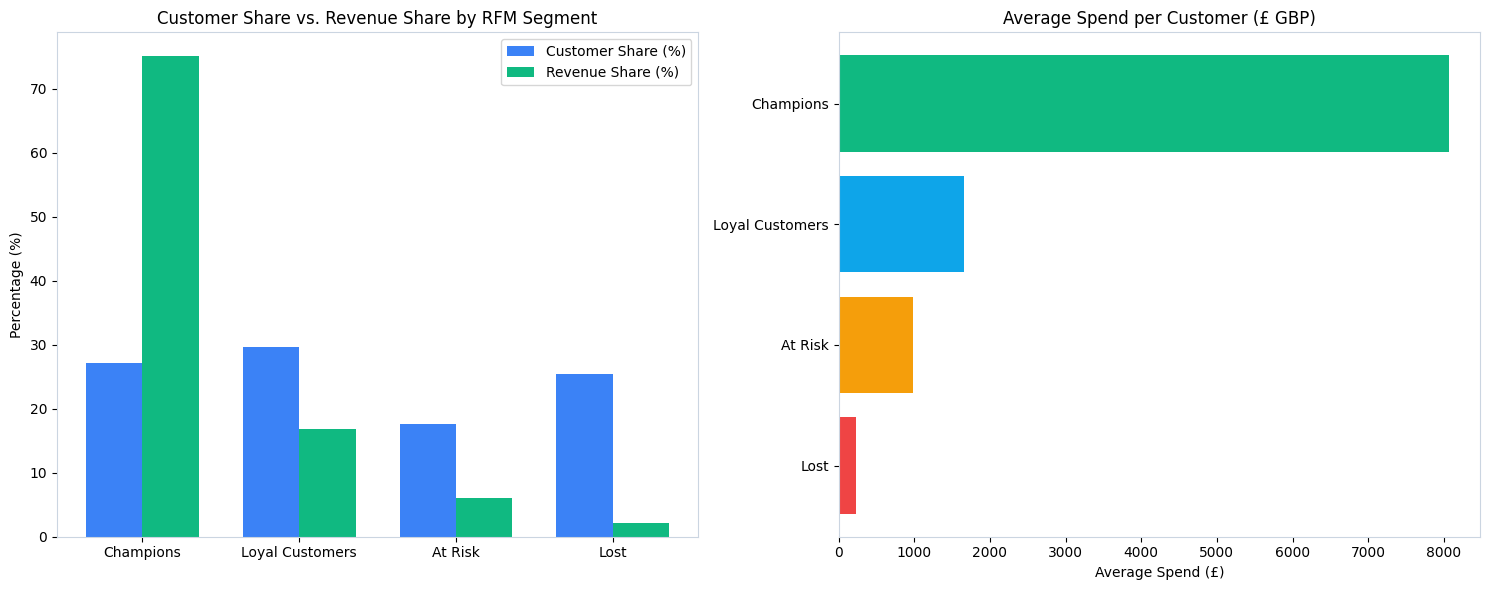

Exported all 5 cleaned analytical tables to output_data/


In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

x = np.arange(len(segment_summary))
w = 0.36
ax1.bar(x - w/2, segment_summary['Customer_Share_%'], width=w, label='Customer Share (%)', color='#3B82F6')
ax1.bar(x + w/2, segment_summary['Revenue_Share_%'], width=w, label='Revenue Share (%)', color='#10B981')
ax1.set_xticks(x)
ax1.set_xticklabels(segment_summary['Segment'])
ax1.set_title('Customer Share vs. Revenue Share by RFM Segment')
ax1.set_ylabel('Percentage (%)')
ax1.legend()

ax2.barh(segment_summary['Segment'], segment_summary['Avg_Spend'], color=['#10B981', '#0EA5E9', '#F59E0B', '#EF4444'])
ax2.invert_yaxis()
ax2.set_title('Average Spend per Customer (£ GBP)')
ax2.set_xlabel('Average Spend (£)')

plt.tight_layout()
plt.show()

out_dir = pathlib.Path('output_data')
out_dir.mkdir(parents=True, exist_ok=True)
audit_df.to_csv(out_dir / '01_data_quality_audit.csv', index=False)
clean_df.to_csv(out_dir / '02_cleaned_retail_transactions.csv', index=False)
returns_df.to_csv(out_dir / '03_isolated_returns_and_cancellations.csv', index=False)
rfm.to_csv(out_dir / '04_customer_rfm_segments.csv', index=False)
retention_matrix.to_csv(out_dir / '05_monthly_cohort_retention.csv')
print('Exported all 5 cleaned analytical tables to output_data/')
